# Decision Trees and Ensemble Learning

## 1. Credit risk scoring project

This section introduces the project for this chapter: predicting whether a bank should lend money to a customer.

### The problem

Imagine you want to buy a phone, but you don't want to pay for it right away. You go to a bank and apply for a loan. You fill in a form with your details: your income, the price of the phone, the amount you want to borrow. The bank looks at this information and makes a decision: approve the loan or decline it.

Historically, banks made this decision manually. Today we can automate it with machine learning. The idea is simple: we take historical data about past customers. For each of them we know what they asked for and what happened afterwards: did they pay back the loan, or did they default?  
We use this data to train a model. Then, when a new customer applies for a loan, the model looks at their information and predicts the risk that this customer will default.

### Binary Classification

This is a binary classification problem. The target variable `y` takes two values:
- `y = 0`: the customer is OK, they paid back their loan
- `y = 1`: the customer defaulted

The model `g` takes the customer information `x` and produces the probability of default:
```
g(xi) -> probability of default
```

So, for each customer, we predict a number between 0 and 1 that says how likely they are to fail to pay back the loan. The bank uses this score to decide whether to lend money to this customer or not. If the model returns a value close to 0, the client is likely to pay back and the bank can approve the loan. If it returns a value close to 1, the client is a likely defaulter and the bank may decline the application.

### The dataset

We will use a credit scoring dataset with information about past customers: how much they earn, what their assets and debt are, whether they have records of previous defaults, and so on.  
The target column is `status`. It says whether the customer defaulted or not.

The dataset is available on https://github.com/k-candidate/CreditScoring.

In the next section we start with cleaning and preparing this dataset for the model.

### What we'll cover in this chapter

This chapter is about decision trees and tree-based ensemble methods:
- How **decision trees** work and how to train them
- How the tree learning algorithm finds the best splits
- How to tune a decision tree to avoid overfitting
- **Ensembles**: **random forest** and **gradient boosting with XGBoost**

## 2. Data cleaning and preparation

In this section we download the credit scoring dataset and prepare it for modeling: we re-encode the categorical columns, fix the encoded missing values, and do the train/validation/test split.

### Downloading the dataset

First we import the libraries we need for this project

In [2]:
import pandas as pd
import numpy as np

import seaborn as sns
from matplotlib import pyplot as plt
%matplotlib inline

The dataset is a CSV file. We put the URL in a variable and download it with `wget`:

In [4]:
data = 'https://raw.githubusercontent.com/k-candidate/mlbookcamp-code/master/chapter-06-trees/CreditScoring.csv'
!wget -nc $data

File ‘CreditScoring.csv’ already there; not retrieving.



In [6]:
# We load it with Pandas
df = pd.read_csv(data)

In [7]:
# We peek inside
df.head()

,Status,Seniority,Home,Time,Age,Marital,Records,Job,Expenses,Income,Assets,Debt,Amount,Price
0,1,9,1,60,30,2,1,3,73,129,0,0,800,846
1,1,17,1,60,58,3,1,1,48,131,0,0,1000,1658
2,2,10,2,36,46,2,2,3,90,200,3000,0,2000,2985
3,1,0,1,60,24,1,1,1,63,182,2500,0,900,1325
4,1,0,1,36,26,1,1,1,46,107,0,0,310,910


Each row is one customer.  
We lowercase the column names for consistency:

In [8]:
df.columns = df.columns.str.lower()

### Re-encoding the categorical variables

The columns `status`, `home`, `marital`, `records` and `job` are categorical, but in the file they are encoded as numbers. For example, `status` is 1, 2 or 0. That's not very intuitive, so we decode them into strings.

Let's first look at the values of `status`:

In [9]:
df.status.value_counts()

status
1    3200
2    1254
0       1
Name: count, dtype: int64

So 3200 customers paid back their loans, 1254 defaulted, and there's one record with the value 0 (an unknown status).  
We use dictionaries and the Pandas `map` method to translate the numbers into strings:

In [10]:
status_values = {
    1: 'ok',
    2: 'default',
    0: 'unk'
}

df.status = df.status.map(status_values)

We do the same for the other categorical columns:

In [11]:
home_values = {
    1: 'rent',
    2: 'owner',
    3: 'private',
    4: 'ignore',
    5: 'parents',
    6: 'other',
    0: 'unk'
}

df.home = df.home.map(home_values)

marital_values = {
    1: 'single',
    2: 'married',
    3: 'widow',
    4: 'separated',
    5: 'divorced',
    0: 'unk'
}

df.marital = df.marital.map(marital_values)

records_values = {
    1: 'no',
    2: 'yes',
    0: 'unk'
}

df.records = df.records.map(records_values)

job_values = {
    1: 'fixed',
    2: 'partime',
    3: 'freelance',
    4: 'others',
    0: 'unk'
}

df.job = df.job.map(job_values)

Now the dataframe is much easier to read:

In [12]:
df.head()

,status,seniority,home,time,age,marital,records,job,expenses,income,assets,debt,amount,price
0,ok,9,rent,60,30,married,no,freelance,73,129,0,0,800,846
1,ok,17,rent,60,58,widow,no,fixed,48,131,0,0,1000,1658
2,default,10,owner,36,46,married,yes,freelance,90,200,3000,0,2000,2985
3,ok,0,rent,60,24,single,no,fixed,63,182,2500,0,900,1325
4,ok,0,rent,36,26,single,no,fixed,46,107,0,0,310,910


### Missing values

Not every problem shows up as a missing value. Let's look at the summary statistics:

In [13]:
df.describe().round()

,seniority,time,age,expenses,income,assets,debt,amount,price
count,4455.0,4455.0,4455.0,4455.0,4455.0,4455.0,4455.0,4455.0,4455.0
mean,8.0,46.0,37.0,56.0,763317.0,1060341.0,404382.0,1039.0,1463.0
std,8.0,15.0,11.0,20.0,8703625.0,10217569.0,6344253.0,475.0,628.0
min,0.0,6.0,18.0,35.0,0.0,0.0,0.0,100.0,105.0
25%,2.0,36.0,28.0,35.0,80.0,0.0,0.0,700.0,1118.0
50%,5.0,48.0,36.0,51.0,120.0,3500.0,0.0,1000.0,1400.0
75%,12.0,60.0,45.0,72.0,166.0,6000.0,0.0,1300.0,1692.0
max,48.0,72.0,68.0,180.0,99999999.0,99999999.0,99999999.0,5000.0,11140.0


The maximum values of `income`, `assets` and `debt` look suspicious: 99999999.  
This dataset encodes missing values as a long number of nines.  
Instead of NaN, "unknown" became 99999999.

We replace these values with NaN:

In [14]:
for c in ['income', 'assets', 'debt']:
    df[c] = df[c].replace(to_replace=99999999, value=np.nan)

After this, `df.describe().round()` shows the true picture: the counts drop (income now has 4421 values instead of 4455, assets 4408, debt 4437) and the maximums become realistic.

In [ ]:
df.describe().round()

,seniority,time,age,expenses,income,assets,debt,amount,price
count,4455.0,4455.0,4455.0,4455.0,4421.0,4408.0,4437.0,4455.0,4455.0
mean,8.0,46.0,37.0,56.0,131.0,5403.0,343.0,1039.0,1463.0
std,8.0,15.0,11.0,20.0,86.0,11573.0,1246.0,475.0,628.0
min,0.0,6.0,18.0,35.0,0.0,0.0,0.0,100.0,105.0
25%,2.0,36.0,28.0,35.0,80.0,0.0,0.0,700.0,1118.0
50%,5.0,48.0,36.0,51.0,120.0,3000.0,0.0,1000.0,1400.0
75%,12.0,60.0,45.0,72.0,165.0,6000.0,0.0,1300.0,1692.0
max,48.0,72.0,68.0,180.0,959.0,300000.0,30000.0,5000.0,11140.0


### Removing the one unknown status

We also have that single customer with status `unk`. Since we only care about the two classes (`ok` and `default`) we remove this row:

In [16]:
df = df[df.status != 'unk'].reset_index(drop=True)

In [17]:
df.describe().round()

,seniority,time,age,expenses,income,assets,debt,amount,price
count,4454.0,4454.0,4454.0,4454.0,4420.0,4407.0,4436.0,4454.0,4454.0
mean,8.0,46.0,37.0,56.0,131.0,5404.0,343.0,1039.0,1463.0
std,8.0,15.0,11.0,20.0,86.0,11574.0,1246.0,475.0,628.0
min,0.0,6.0,18.0,35.0,0.0,0.0,0.0,100.0,105.0
25%,2.0,36.0,28.0,35.0,80.0,0.0,0.0,700.0,1117.0
50%,5.0,48.0,36.0,51.0,120.0,3000.0,0.0,1000.0,1400.0
75%,12.0,60.0,45.0,72.0,165.0,6000.0,0.0,1300.0,1692.0
max,48.0,72.0,68.0,180.0,959.0,300000.0,30000.0,5000.0,11140.0


This leaves 4454 rows.

### Train/validation/test split

Now we split the data. As in the previous chapters, we do it in two steps: first we split off the test set (20%), then we split the rest into train and validation (75/25 of what remains, which gives us the 60/20/20 distribution):

In [18]:
from sklearn.model_selection import train_test_split

df_full_train, df_test = train_test_split(df, test_size=0.2, random_state=11)
df_train, df_val = train_test_split(df_full_train, test_size=0.25, random_state=11)

We reset the indexes so they are fresh and unique in each dataframe:

In [19]:
df_train = df_train.reset_index(drop=True)
df_val = df_val.reset_index(drop=True)
df_test = df_test.reset_index(drop=True)

### Preparing the target variable

The models give us a probability, so the target needs to be a number. We encode `status`: 0 for `ok`, 1 for `default`:

In [20]:
y_train = (df_train.status == 'default').astype('int').values
y_val = (df_val.status == 'default').astype('int').values
y_test = (df_test.status == 'default').astype('int').values

Finally, we delete `status` from the dataframes, otherwise we would use the target as a feature, and the model would learn to cheat:

In [21]:
del df_train['status']
del df_val['status']
del df_test['status']

In [22]:
df_train

,seniority,home,time,age,marital,records,job,expenses,income,assets,debt,amount,price
0,10,owner,36,36,married,no,freelance,75,0.0,10000.0,0.0,1000,1400
1,6,parents,48,32,single,yes,fixed,35,85.0,0.0,0.0,1100,1330
2,1,parents,48,40,married,no,fixed,75,121.0,0.0,0.0,1320,1600
3,1,parents,48,23,single,no,partime,35,72.0,0.0,0.0,1078,1079
4,5,owner,36,46,married,no,freelance,60,100.0,4000.0,0.0,1100,1897
...,...,...,...,...,...,...,...,...,...,...,...,...,...
2667,18,private,36,45,married,no,fixed,45,220.0,20000.0,0.0,800,1600
2668,7,private,60,29,married,no,fixed,60,51.0,3500.0,500.0,1000,1290
2669,1,parents,24,19,single,no,fixed,35,28.0,0.0,0.0,400,600
2670,15,owner,48,43,married,no,freelance,60,100.0,18000.0,0.0,2500,2976


The data is ready. In the next section we train our first decision tree.

## 3. Decision Trees

In this section:
- we train our first decision tree with scikit-learn on the credit scoring data
- see what overfitting looks like
- and learn how to control the size of a tree.

### What a decision tree looks like

At its core, a decision tree is just a set of if/else rules. For our credit risk problem, we could write one by hand:

In [23]:
def assess_risk(client):
    if client['records'] == 'yes':
        if client['job'] == 'parttime':
            return 'default'
        else:
            return 'ok'
    else:
        if client['assets'] > 6000:
            return 'ok'
        else:
            return 'default'

Reading it from top to bottom: if the customer has records of previous defaults and works part-time, we predict `default`. If they have records but a different job, `ok`. If they have no records, we look at their assets: more than 6000 means `ok`, otherwise `default`.

<img src="https://github.com/k-candidate/machine-learning-zoomcamp/raw/main/06-trees/images/03-decision-trees-01-risk-rules-tree-imagegen.jpg" alt="Decision Tree" style="max-width: 100%; height: auto; display: block; margin: 0 auto;">

Let's take one customer from the training data and check what the rules say about them:

In [24]:
xi = df_train.iloc[0].to_dict()
assess_risk(xi)

'ok'

Of course, writing rules by hand doesn't scale. The point of the decision tree algorithm is that it learns these rules from data automatically.

### Training a decision tree

We use `DecisionTreeClassifier` from scikit-learn. The features are mixed: numeric columns and categorical ones we encoded as strings. We turn each row into a dictionary, fill the missing values with 0, and use `DictVectorizer` to convert the dictionaries into a feature matrix:

In [25]:
from sklearn.tree import DecisionTreeClassifier
from sklearn.feature_extraction import DictVectorizer
from sklearn.metrics import roc_auc_score
from sklearn.tree import export_text

In [26]:
train_dicts = df_train.fillna(0).to_dict(orient='records')

dv = DictVectorizer(sparse=False)
X_train = dv.fit_transform(train_dicts)

`DictVectorizer` one-hot encodes the categorical features (it creates columns like `job=partime` and `records=no`) and leaves the numeric ones unchanged.

Now we train the tree:

In [27]:
dt = DecisionTreeClassifier()
dt.fit(X_train, y_train)

,"criterion criterion: {""gini"", ""entropy"", ""log_loss""}, default=""gini""The function to measure the quality of a split. Supported criteria are""gini"" for the Gini impurity and ""log_loss"" and ""entropy"" both for theShannon information gain, see :ref:`tree_mathematical_formulation`.",'gini'
,"splitter splitter: {""best"", ""random""}, default=""best""The strategy used to choose the split at each node. Supportedstrategies are ""best"" to choose the best split and ""random"" to choosethe best random split among considered features for this split.",'best'
,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",None
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: int, float or {""sqrt"", ""log2""}, default=NoneThe number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None, then `max_features=n_features`.Note: splitting may inspect more than ``max_features`` features ifneeded to find a valid split.",None
,"random_state random_state: int, RandomState instance or None, default=NoneControls the randomness of the estimator. The features are alwaysrandomly permuted at each split, even if ``splitter`` is set to``""best""``. When ``max_features < n_features``, the algorithm willselect ``max_features`` at random at each split before finding the bestsplit among them. But the best found split may vary across differentruns, even if ``max_features=n_features``. That is the case, if theimprovement of the criterion is identical for several splits and onesplit has to be selected at random. To obtain a deterministic behaviourduring fitting, ``random_state`` has to be fixed to an integer.See :term:`Glossary <random_state>` for details.",None
,"max_leaf_nodes max_leaf_nodes: int, default=NoneGrow a tree with ``max_leaf_nodes`` in best-first fashion.Best nodes are defined as relative reduction in impurity.If None then unlimited number of leaf nodes.",None
,"min_impurity_decrease min_impurity_decrease: float, default=0.0A node will be split if this split induces a decrease of the impuritygreater than or equal to this value.The weighted impurity decrease equation is the following:: N_t / N * (impurity - N_t_R / N_t * right_impurity - N_t_L / N_t * left_impurity)where ``N`` is the total number of samples, ``N_t`` is the number ofsamples at the current node, ``N_t_L`` is the number of sampl

And check how it performs on the validation set:

In [28]:
val_dicts = df_val.fillna(0).to_dict(orient='records')
X_val = dv.transform(val_dicts)

y_pred = dt.predict_proba(X_val)[:, 1]
roc_auc_score(y_val, y_pred)

0.6503717517134484

### Overfitting

An AUC of 0.65 is **not** great. What about the data the model was trained on?

In [29]:
y_pred = dt.predict_proba(X_train)[:, 1]
roc_auc_score(y_train, y_pred)

1.0

AUC of 1.0 on training but 0.65 on validation: the tree memorized the training data.  
It learned one specific rule per customer, so on the customers it has seen it's perfect, but these rules don't generalize to unseen customers.  
This is **overfitting: memorizing the data but failing to generalize.**

<img src="https://github.com/k-candidate/machine-learning-zoomcamp/raw/main/06-trees/images/03-decision-trees-05-memorizing-imagegen.jpg" alt="Decision Tree Overfitting" style="max-width: 100%; height: auto; display: block; margin: 0 auto;">

**The reason is that we let the tree grow without limits, so it became very deep: it kept splitting until every leaf was pure.**

### Controlling the size of the tree

We can restrict the depth of the tree with the `max_depth` parameter. A shallow tree cannot memorize each customer, it has to learn broader rules:

In [30]:
dt = DecisionTreeClassifier(max_depth=2)
dt.fit(X_train, y_train)

,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",2
,"criterion criterion: {""gini"", ""entropy"", ""log_loss""}, default=""gini""The function to measure the quality of a split. Supported criteria are""gini"" for the Gini impurity and ""log_loss"" and ""entropy"" both for theShannon information gain, see :ref:`tree_mathematical_formulation`.",'gini'
,"splitter splitter: {""best"", ""random""}, default=""best""The strategy used to choose the split at each node. Supportedstrategies are ""best"" to choose the best split and ""random"" to choosethe best random split among considered features for this split.",'best'
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: int, float or {""sqrt"", ""log2""}, default=NoneThe number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None, then `max_features=n_features`.Note: splitting may inspect more than ``max_features`` features ifneeded to find a valid split.",None
,"random_state random_state: int, RandomState instance or None, default=NoneControls the randomness of the estimator. The features are alwaysrandomly permuted at each split, even if ``splitter`` is set to``""best""``. When ``max_features < n_features``, the algorithm willselect ``max_features`` at random at each split before finding the bestsplit among them. But the best found split may vary across differentruns, even if ``max_features=n_features``. That is the case, if theimprovement of the criterion is identical for several splits and onesplit has to be selected at random. To obtain a deterministic behaviourduring fitting, ``random_state`` has to be fixed to an integer.See :term:`Glossary <random_state>` for details.",None
,"max_leaf_nodes max_leaf_nodes: int, default=NoneGrow a tree with ``max_leaf_nodes`` in best-first fashion.Best nodes are defined as relative reduction in impurity.If None then unlimited number of leaf nodes.",None
,"min_impurity_decrease min_impurity_decrease: float, default=0.0A node will be split if this split induces a decrease of the impuritygreater than or equal to this value.The weighted impurity decrease equation is the following:: N_t / N * (impurity - N_t_R / N_t * right_impurity - N_t_L / N_t * left_impurity)where ``N`` is the total number of samples, ``N_t`` is the number ofsamples at the current node, ``N_t_L`` is the number of samples 

In [31]:
y_pred = dt.predict_proba(X_train)[:, 1]
auc = roc_auc_score(y_train, y_pred)
print('train:', auc)

y_pred = dt.predict_proba(X_val)[:, 1]
auc = roc_auc_score(y_val, y_pred)
print('val:', auc)

train: 0.7054989859726213
val: 0.6685264343319367


The training AUC went down, but the validation AUC went up. We traded some accuracy on known customers for the ability to generalize.

### Looking inside the tree

To see the rules the tree learned, we use `export_text`:

In [32]:
print(export_text(dt, feature_names=list(dv.get_feature_names_out())))

|--- records=yes <= 0.50
|   |--- job=partime <= 0.50
|   |   |--- class: 0
|   |--- job=partime >  0.50
|   |   |--- class: 1
|--- records=yes >  0.50
|   |--- seniority <= 6.50
|   |   |--- class: 1
|   |--- seniority >  6.50
|   |   |--- class: 0



This is the tree in text form: customers without records and with more than 6.5 years of seniority are predicted as `ok` (class 0), customers with records who work part-time as `default` (class 1), and so on.

<img src="https://github.com/k-candidate/machine-learning-zoomcamp/raw/main/06-trees/images/03-decision-trees-06-learned-rules-imagegen.jpg" alt="Size 2 Decision Tree learned rules" style="max-width: 100%; height: auto; display: block; margin: 0 auto;">

**A tree with a depth of 1 (a single condition) is called a decision stump**. It's not really a tree, just one split, and it's the simplest possible decision tree.

<img src="https://github.com/k-candidate/machine-learning-zoomcamp/raw/main/06-trees/images/03-decision-trees-07-decision-stump-imagegen.jpg" alt="Size 3 Decision Tree and Decision Stump" style="max-width: 100%; height: auto; display: block; margin: 0 auto;">

The question is: how does the learning algorithm decide which condition and which threshold to use at each split? That's the topic of the next section.

## 4. Decision tree learning algorithm

In this section we look inside the decision tree learning algorithm: how it finds the best condition for a split, what impurity is, and when it stops splitting.

### Tree vocabulary

First, the names for the parts of a tree:
- A <u>**node**</u> contains a **condition**, for example `assets > 3000`.
- Two <u>**branches**</u> go out of it: one for "true" and one for "false".
- The **node at the top** is the <u>**root**</u>; every node except the leaves is a parent of two other nodes.
- The **nodes at the very bottom** are <u>**leaves**</u> (**decision nodes**): this is **where the tree stops and the prediction is made**.
- The <u>**depth**</u> of a tree is the **number of levels**: the **length of the longest path from the root to a leaf**.

To understand how the algorithm learns such a tree, we take a small toy dataset instead of the full credit scoring data.

### Finding the best split for one column

We take eight customers with one feature, `assets`, and the target, `status`:

In [44]:
data = [
    [8000, 'default'],
    [2000, 'default'],
    [   0, 'default'],
    [5000, 'ok'],
    [5000, 'ok'],
    [4000, 'ok'],
    [9000, 'ok'],
    [3000, 'default'],
]

df_example = pd.DataFrame(data, columns=['assets', 'status'])

In [34]:
df_example

,assets,status
0,8000,default
1,2000,default
2,0,default
3,5000,ok
4,5000,ok
5,4000,ok
6,9000,ok
7,3000,default


We want to build a decision stump, a tree with one condition, `assets > T`. The question is: which threshold `T` is the best?

The condition splits the data into two parts: the left side where the condition is false (`assets <= T`) and the right side where it is true (`assets > T`). The candidate thresholds are the values in the middle between the observed values. If we sort by `assets`, the candidates are:

In [45]:
df_example.sort_values('assets')

,assets,status
2,0,default
1,2000,default
7,3000,default
5,4000,ok
4,5000,ok
3,5000,ok
0,8000,default
6,9000,ok


In [46]:
Ts = [0, 2000, 3000, 4000, 5000, 8000]

Thresholds 0 and 8000 don't really make sense (one side would be empty), but the algorithm still tries them. Let's split with `T = 4000`:

In [47]:
T = 4000
df_left = df_example[df_example.assets <= T]
df_right = df_example[df_example.assets > T]

display(df_left)
print(df_left.status.value_counts(normalize=True))
display(df_right)
print(df_right.status.value_counts(normalize=True))

,assets,status
1,2000,default
2,0,default
5,4000,ok
7,3000,default


status
default    0.75
ok         0.25
Name: proportion, dtype: float64


,assets,status
0,8000,default
3,5000,ok
4,5000,ok
6,9000,ok


status
ok         0.75
default    0.25
Name: proportion, dtype: float64


The left side has four customers: three `default` and one `ok`. The right side: three `ok` and one `default`.

For each side we predict the majority class: the most frequent status.  
Left: `default`.  
Right: `ok`.  
The mistake rate on the left is 1/4 = 25% (the one `ok` customer), and on the right also 1/4 = 25%.

This **mistake rate** is called the <u>**misclassification rate**</u>, and it is one way of measuring how impure a group is.  
A pure group contains only one class (zero misclassification rate). We can compute the rates for both sides with `value_counts(normalize=True)` and average them, weighted by the group sizes:

In [58]:
for T in Ts:
    print(T)
    df_left = df_example[df_example.assets <= T]
    df_right = df_example[df_example.assets > T]
    
    display(df_left)
    print(df_left.status.value_counts(normalize=True))
    display(df_right)
    print(df_right.status.value_counts(normalize=True))

    print()

0


,assets,status
2,0,default


status
default    1.0
Name: proportion, dtype: float64


,assets,status
0,8000,default
1,2000,default
3,5000,ok
4,5000,ok
5,4000,ok
6,9000,ok
7,3000,default


status
ok         0.571429
default    0.428571
Name: proportion, dtype: float64

2000


,assets,status
1,2000,default
2,0,default


... (15 outputs left out)

,assets,status
0,8000,default
1,2000,default
2,0,default
3,5000,ok
4,5000,ok
5,4000,ok
7,3000,default


status
default    0.571429
ok         0.428571
Name: proportion, dtype: float64


,assets,status
6,9000,ok


status
ok    1.0
Name: proportion, dtype: float64



To visualize it in an easier way:

In [57]:
print(f"{'T':<5}{'decision LEFT':<16}{'impurity LEFT':<16}{'decision RIGHT':<16}{'impurity RIGHT':<16}{'AVG':<5}")

rows = []
for T in Ts:
    df_left = df_example[df_example.assets <= T]
    df_right = df_example[df_example.assets > T]
    
    ok_left = (df_left.status == 'ok').mean() if len(df_left) > 0 else 0.0
    ok_right = (df_right.status == 'ok').mean() if len(df_right) > 0 else 0.0
    
    dec_l = 'ok' if ok_left > 0.5 else 'default'
    imp_l = ok_left if dec_l == 'default' else (1.0 - ok_left)
    
    dec_r = 'ok' if ok_right >= 0.5 else 'default'
    imp_r = ok_right if dec_r == 'default' else (1.0 - ok_right)
    
    imp_l_pct = round(imp_l * 100)
    imp_r_pct = round(imp_r * 100)
    avg_pct = (imp_l_pct + imp_r_pct) // 2

    print(f"{T:<5}{dec_l:<16}{f'{imp_l_pct}%':<16}{dec_r:<16}{f'{imp_r_pct}%':<16}{f'{avg_pct}%':<5}")


T    decision LEFT   impurity LEFT   decision RIGHT  impurity RIGHT  AVG  
0    default         0%              ok              43%             21%  
2000 default         0%              ok              33%             16%  
3000 default         0%              ok              20%             10%  
4000 default         25%             ok              25%             25%  
5000 default         50%             ok              50%             50%  
8000 default         43%             ok              0%              21%  


The best threshold is `T = 3000`: the average impurity is only 10%. So the best split for this column is `assets > 3000`.

```
       ASSETS > 3000 
        /         \                            
   FALSE           TRUE
   DEFAULT         OK
```

### Checking multiple features

Real data has many features, and the algorithm needs to find the best split among all of them. Let's add a second feature, `debt`:

In [60]:
data = [
    [8000, 3000, 'default'],
    [2000, 1000, 'default'],
    [   0, 1000, 'default'],
    [5000, 1000, 'ok'],
    [5000, 1000, 'ok'],
    [4000, 1000, 'ok'],
    [9000,  500, 'ok'],
    [3000, 2000, 'default'],
]

df_example = pd.DataFrame(data, columns=['assets', 'debt', 'status'])
df_example

,assets,debt,status
0,8000,3000,default
1,2000,1000,default
2,0,1000,default
3,5000,1000,ok
4,5000,1000,ok
5,4000,1000,ok
6,9000,500,ok
7,3000,2000,default


For `debt` the candidate thresholds are `[500, 1000, 2000]`. We put all thresholds in a dictionary and loop over both features and all their thresholds:

In [61]:
thresholds = {
    'assets': [0, 2000, 3000, 4000, 5000, 8000],
    'debt': [500, 1000, 2000]
}

for feature, Ts in thresholds.items():
    print('#####################')
    print(feature)
    for T in Ts:
        print(T)
        df_left = df_example[df_example[feature] <= T]
        df_right = df_example[df_example[feature] > T]

        display(df_left)
        print(df_left.status.value_counts(normalize=True))
        display(df_right)
        print(df_right.status.value_counts(normalize=True))

        print()
    print('#####################')

#####################
assets
0


,assets,debt,status
2,0,1000,default


status
default    1.0
Name: proportion, dtype: float64


,assets,debt,status
0,8000,3000,default
1,2000,1000,default
3,5000,1000,ok
4,5000,1000,ok
5,4000,1000,ok
6,9000,500,ok
7,3000,2000,default


status
ok         0.571429
default    0.428571
Name: proportion, dtype: float64

2000


,assets,debt,status
1,2000,1000,default
2,0,1000,default


... (27 outputs left out)

,assets,debt,status
1,2000,1000,default
2,0,1000,default
3,5000,1000,ok
4,5000,1000,ok
5,4000,1000,ok
6,9000,500,ok
7,3000,2000,default


status
ok         0.571429
default    0.428571
Name: proportion, dtype: float64


,assets,debt,status
0,8000,3000,default


status
default    1.0
Name: proportion, dtype: float64

#####################


For `debt`, the best split gives an average impurity of 16%, worse than the 10% we got with `assets`.  
So the best split overall is still `assets > 3000`. With more features we would simply add more rows to this comparison.

### The split-finding algorithm

In pseudocode, finding the best split works like this:

```
FOR each feature in FEATURES:
    FIND all thresholds for the feature
    FOR each threshold in thresholds:
        SPLIT the dataset using "feature > threshold" condition
        COMPUTE the impurity of this split
SELECT the condition with the LOWEST IMPURITY
```

**The misclassification rate is not the only impurity measure. Scikit-learn uses more sensitive criteria: Gini impurity and entropy. For regression trees the equivalent is MSE.**  
**The idea stays the same: pick the split with the lowest impurity. And while we looked at classification here, decision trees can also solve regression problems.**

### Stopping criteria

After the root is split, the algorithm applies the same procedure recursively to the left and right sides. When does it stop?
- The group is already pure: the misclassification rate is 0%, no point in splitting further.
- The tree reached the maximum depth limit: controlled by `max_depth`.
- The group is too small to split: controlled by `min_samples_leaf`.
- The maximum number of leaves (decision nodes) was reached.

<u>**These stopping criteria are what keep a tree from overfitting.**</u>

### The full algorithm

Putting everything together:
- Find the best split: for every feature, try all possible thresholds and pick the condition with the lowest impurity.
- If the stopping criteria are not met (max depth not reached, groups large enough and not pure), repeat for the left side and the right side.

In the next section we tune `max_depth` and `min_samples_leaf` for our credit scoring project.

## 5. Decision trees parameter tuning

In this section we tune the decision tree: we try different values of `max_depth` and `min_samples_leaf`, pick the combination with the best validation AUC, and look at the final tree.

### Which parameters to tune

`DecisionTreeClassifier` has many parameters: `criterion`, which is the impurity measure, `max_depth`, `min_samples_leaf`, and others.  
The two that matter most are:
- `max_depth`: the maximum number of levels. It limits how specific the rules can get.
- `min_samples_leaf`: the minimum number of samples in a leaf. It prevents the tree from creating leaves that cover just one or two customers.

Tuning means selecting the values that give the best score on the validation set: AUC in our case.

### Selecting max_depth

We start with `max_depth` alone. We try depths from 1 to 20, plus `None` (no limit), and record the validation AUC for each:

In [62]:
depths = [1, 2, 3, 4, 5, 6, 10, 15, 20, None]

for depth in depths: 
    dt = DecisionTreeClassifier(max_depth=depth)
    dt.fit(X_train, y_train)
    
    y_pred = dt.predict_proba(X_val)[:, 1]
    auc = roc_auc_score(y_val, y_pred)
    
    print('%4s -> %.3f' % (depth, auc))

   1 -> 0.606
   2 -> 0.669
   3 -> 0.739
   4 -> 0.761
   5 -> 0.767
   6 -> 0.762
  10 -> 0.701
  15 -> 0.667
  20 -> 0.651
None -> 0.653


Depths 4, 5 and 6 are the best (AUC around 0.76).
**Trees that are too shallow underfit; deep trees overfit and end up worse than the simple ones.**

### Adding min_samples_leaf

Now we take the promising depths (4, 5 and 6) and for each of them try several values of `min_samples_leaf`. We store the results as tuples in a list:

In [63]:
scores = []

for depth in [4, 5, 6]:
    for s in [1, 5, 10, 15, 20, 500, 100, 200]:
        dt = DecisionTreeClassifier(max_depth=depth, min_samples_leaf=s)
        dt.fit(X_train, y_train)

        y_pred = dt.predict_proba(X_val)[:, 1]
        auc = roc_auc_score(y_val, y_pred)
        
        scores.append((depth, s, auc))

Then we put the scores into a dataframe:

In [64]:
columns = ['max_depth', 'min_samples_leaf', 'auc']
df_scores = pd.DataFrame(scores, columns=columns)

The sorted dataframe is hard to scan. It's easier to reshape it: rows for `min_samples_leaf`, columns for `max_depth`, and the AUC in the cells. That's what the `pivot` method does:

In [65]:
df_scores_pivot = df_scores.pivot(index='min_samples_leaf', columns=['max_depth'], values=['auc'])
df_scores_pivot.round(3)

auc              
max_depth             4      5      6
min_samples_leaf                     
1                 0.761  0.767  0.758
5                 0.761  0.768  0.761
10                0.761  0.762  0.778
15                0.764  0.772  0.785
20                0.761  0.774  0.773
100               0.756  0.763  0.776
200               0.747  0.759  0.768
500               0.680  0.680  0.680

Even easier to read as a heatmap. The best cell is the lightest one:

<Axes: xlabel='None-max_depth', ylabel='min_samples_leaf'>

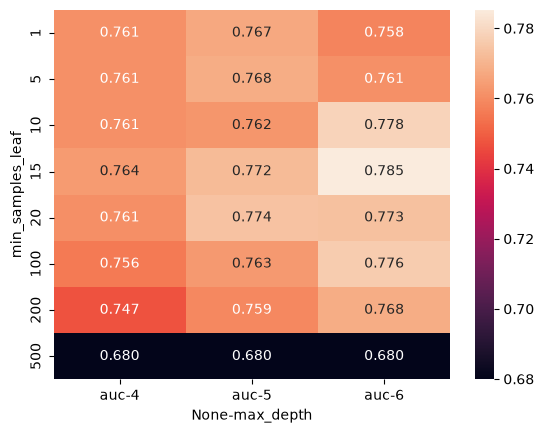

In [66]:
sns.heatmap(df_scores_pivot, annot=True, fmt=".3f")

The best combination is `max_depth=6` and `min_samples_leaf=15`, with an AUC of 0.785, better than anything we saw when tuning `max_depth` alone.

Note that we only searched depths 4-6 for the second parameter. On a large dataset it would be too slow to try every combination, so we first select `max_depth` and then tune the rest. On this small dataset we could afford to check more combinations, and if we did, other close pairs would show up. It's a good habit to start with a coarse search and refine it.

### The final tree

Let's train the tree with the tuned parameters and look at the rules it learned:

In [67]:
dt = DecisionTreeClassifier(max_depth=6, min_samples_leaf=15)
dt.fit(X_train, y_train)

print(export_text(dt, feature_names=list(dv.get_feature_names_out())))

|--- records=yes <= 0.50
|   |--- job=partime <= 0.50
|   |   |--- income <= 74.50
|   |   |   |--- assets <= 4250.00
|   |   |   |   |--- income <= 20.00
|   |   |   |   |   |--- seniority <= 1.50
|   |   |   |   |   |   |--- class: 1
|   |   |   |   |   |--- seniority >  1.50
|   |   |   |   |   |   |--- class: 1
|   |   |   |   |--- income >  20.00
|   |   |   |   |   |--- expenses <= 71.00
|   |   |   |   |   |   |--- class: 0
|   |   |   |   |   |--- expenses >  71.00
|   |   |   |   |   |   |--- class: 1
|   |   |   |--- assets >  4250.00
|   |   |   |   |--- debt <= 1600.00
|   |   |   |   |   |--- seniority <= 2.50
|   |   |   |   |   |   |--- class: 0
|   |   |   |   |   |--- seniority >  2.50
|   |   |   |   |   |   |--- class: 0
|   |   |   |   |--- debt >  1600.00
|   |   |   |   |   |--- class: 1
|   |   |--- income >  74.50
|   |   |   |--- seniority <= 5.50
|   |   |   |   |--- amount <= 1330.00
|   |   |   |   |   |--- assets <= 3326.00
|   |   |   |   |   |   |--- clas

This tree is still readable, unlike the unlimited one from before.

One caution: when you scan the results, watch out for parameter values that don't make sense, like `nan` creeping into the grid. A combination can show a good score by accident: check that the values you pick actually control the size of the tree the way you intend.

## 6. Ensembles and Random Forest

In this section:
- we combine many decision trees into one model
- We start with the idea behind it: asking a board of experts instead of trusting a single one
- then build a random forest with scikit-learn
- and tune the random forest's three main parameters.

### Board of Experts

So far we score a loan application with a single decision tree: the features of the client go in, the tree outputs the probability of default, and the bank uses this score to approve or reject the application.

**Instead of one expert, imagine a board of five experts. When a client submits an application, it goes to each of them. Every expert looks at the application and decides: approve or reject. The final decision is made by majority vote. The idea is that the collective opinion of five experts is more reliable than the opinion of one.**

We can do the same with models. Instead of five people, we have five models, g1, g2 and so on, and each of them returns its probability of default. To combine them, we take the average of these probabilities:

$$\frac{1}{n} \sum P_i = \frac{1}{n} (p_1 + p_2 + \dots + p_n)$$

<u>**Combining several models this way is called ensembling, and the individual models are often called "weak learners": each one alone is not great, but together they are stronger than any single model.**</u>

### Random Forest

<u>**When the models we ensemble are decision trees, the ensemble is called a random forest. But it cannot be just any group of trees: the trees need to be different from each other. If we simply train the same tree several times on the same data with the same parameters, we get identical trees that produce identical predictions, and averaging them gives exactly the same result as a single tree.**</u>

<u>**The "random" in random forest is what makes the trees diverse: each tree gets a random subset of features, and, depending on the `bootstrap` parameter, a randomly resampled copy of the training data.**</u>  
**To see the idea, suppose we have three features: `assets`, `debt` and `price`, and we train three trees. The first tree may see `assets` and `debt`, the second `assets` and `price`, and the third `debt` and `price`. Each tree gives its own prediction ($p_1$, $p_2$ and $p_3$), and the final prediction is the average: $\frac{p_1 + p_2 + p_3}{3}$.**

Let's make one thing very clear: <u>**Random Forest is an example of ensemble learning**</u>.

<img src="https://github.com/k-candidate/machine-learning-zoomcamp/raw/main/06-trees/images/06-random-forest-02-random-forest-imagegen.jpg" alt="Random Forest" style="max-width: 100%; height: auto; display: block; margin: 0 auto;">

In scikit-learn, random forest lives in the `ensemble` package.  
Let's take our credit scoring data and train a random forest with a varying number of trees, from 10 to 200 with a step of 10, and see how the number of trees affects the AUC on validation:

In [68]:
from sklearn.ensemble import RandomForestClassifier

scores = []

for n in range(10, 201, 10):
    rf = RandomForestClassifier(n_estimators=n, random_state=1)
    rf.fit(X_train, y_train)

    y_pred = rf.predict_proba(X_val)[:, 1]
    auc = roc_auc_score(y_val, y_pred)

    scores.append((n, auc))

Then we put the scores into a dataframe and plot them:

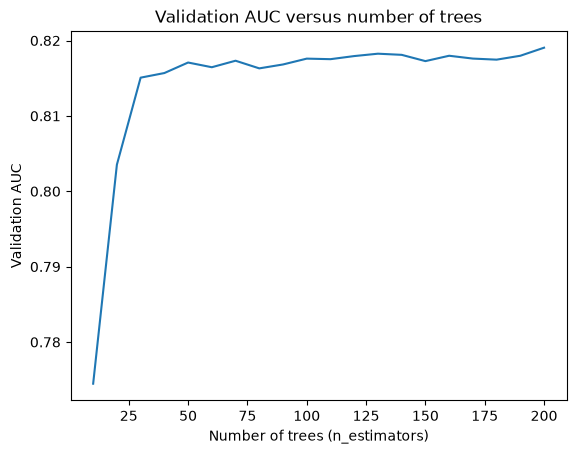

In [70]:
df_scores = pd.DataFrame(scores, columns=['n_estimators', 'auc'])
plt.plot(df_scores.n_estimators, df_scores.auc)
plt.xlabel("Number of trees (n_estimators)")
plt.ylabel("Validation AUC")
plt.title("Validation AUC versus number of trees")
plt.show();

**The curve grows quickly at the beginning and then stabilizes: after some number of trees, adding more of them does not improve the score. Still, more trees never hurt the quality, the curve stays flat, so the main cost of extra trees is training time, not accuracy. This is why `n_estimators` is usually set to "as many as you can afford", and we tune the other parameters first.**

### Tuning max_depth

Now let's tune `max_depth`, the maximum depth of each tree in the forest. We use the same loop, but this time we try three values of `max_depth` (5, 10 and 15) and for each of them we again iterate over the number of trees:

In [71]:
scores = []

for d in [5, 10, 15]:
    for n in range(10, 201, 10):
        rf = RandomForestClassifier(n_estimators=n,
                                    max_depth=d,
                                    random_state=1)
        rf.fit(X_train, y_train)

        y_pred = rf.predict_proba(X_val)[:, 1]
        auc = roc_auc_score(y_val, y_pred)

        scores.append((d, n, auc))

To compare the three depths, we plot each of them as a separate line:

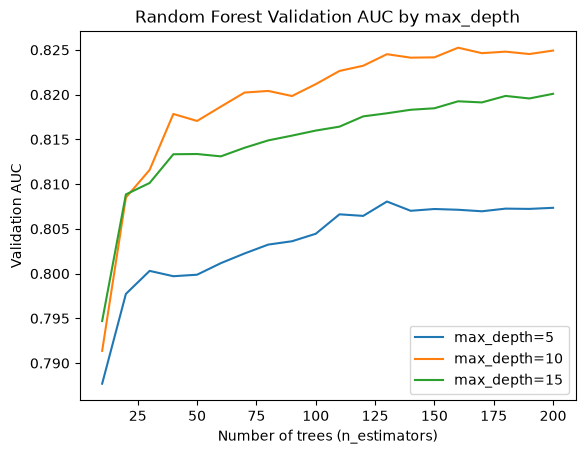

In [74]:
columns = ['max_depth', 'n_estimators', 'auc']
df_scores = pd.DataFrame(scores, columns=columns)

for d in [5, 10, 15]:
    df_subset = df_scores[df_scores.max_depth == d]

    plt.plot(df_subset.n_estimators, df_subset.auc,
             label='max_depth=%d' % d)
    plt.xlabel("Number of trees (n_estimators)")
    plt.ylabel("Validation AUC")
    plt.title("Random Forest Validation AUC by max_depth")

plt.legend()

The curves for `max_depth=10` and `max_depth=15` are clearly better than the one for `max_depth=5`, and `max_depth=10` is the best of the three. So we fix it:

In [75]:
max_depth = 10

### Tuning min_samples_leaf

The third parameter is `min_samples_leaf`: the minimal number of observations allowed in a leaf of a tree.  
We repeat the same procedure: keep `max_depth` fixed at 10 and try `min_samples_leaf` of 1, 3, 5, 10 and 50, each combined with a varying number of trees:

In [76]:
scores = []

for s in [1, 3, 5, 10, 50]:
    for n in range(10, 201, 10):
        rf = RandomForestClassifier(n_estimators=n,
                                    max_depth=max_depth,
                                    min_samples_leaf=s,
                                    random_state=1)
        rf.fit(X_train, y_train)

        y_pred = rf.predict_proba(X_val)[:, 1]
        auc = roc_auc_score(y_val, y_pred)

        scores.append((s, n, auc))

And plot all five curves, giving each value its own color:

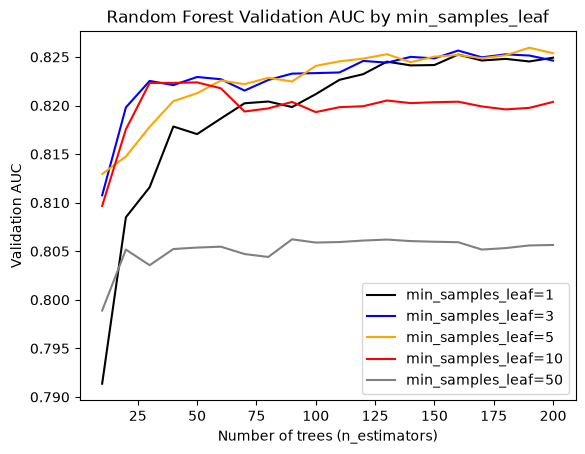

In [78]:
columns = ['min_samples_leaf', 'n_estimators', 'auc']
df_scores = pd.DataFrame(scores, columns=columns)

colors = ['black', 'blue', 'orange', 'red', 'grey']
values = [1, 3, 5, 10, 50]

for s, col in zip(values, colors):
    df_subset = df_scores[df_scores.min_samples_leaf == s]

    plt.plot(df_subset.n_estimators, df_subset.auc,
             color=col,
             label='min_samples_leaf=%d' % s)
    plt.xlabel("Number of trees (n_estimators)")
    plt.ylabel("Validation AUC")
    plt.title("Random Forest Validation AUC by min_samples_leaf")

plt.legend();

The curves with small values 1, 3 and 5 are close to each other at the top, while 10 and especially 50 are worse. We take `min_samples_leaf=3:`

In [79]:
min_samples_leaf = 3

### The final model

With the parameters selected, we train the final random forest with 200 trees:

In [80]:
rf = RandomForestClassifier(n_estimators=200,
                            max_depth=max_depth,
                            min_samples_leaf=min_samples_leaf,
                            random_state=1)
rf.fit(X_train, y_train)

,"n_estimators n_estimators: int, default=100The number of trees in the forest... versionchanged:: 0.22 The default value of ``n_estimators`` changed from 10 to 100 in 0.22.",200
,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",10
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",3
,"random_state random_state: int, RandomState instance or None, default=NoneControls both the randomness of the bootstrapping of the samples usedwhen building trees (if ``bootstrap=True``) and the sampling of thefeatures to consider when looking for the best split at each node(if ``max_features < n_features``).See :term:`Glossary <random_state>` for details.",1
,"criterion criterion: {""gini"", ""entropy"", ""log_loss""}, default=""gini""The function to measure the quality of a split. Supported criteria are""gini"" for the Gini impurity and ""log_loss"" and ""entropy"" both for theShannon information gain, see :ref:`tree_mathematical_formulation`.Note: This parameter is tree-specific.",'gini'
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: {""sqrt"", ""log2"", None}, int or float, default=""sqrt""The number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None, then `max_features=n_features`... versionchanged:: 1.1 The default of `max_features` changed from `""auto""` to `""sqrt""`.Note: the search for a split does not stop until at least onevalid partition of the node samples is found, even if it requires toeffectively inspect more than ``max_features`` features.",'sqrt'
,"max_leaf_nodes max_leaf_nodes: int, default=NoneGrow trees with ``max_leaf_nodes`` in best-first fashion.Best nodes are defined as relative reduction in impurity.If None then unlimited number of leaf nodes.",None
,"min_impurity_decrease min_impurity_decrease: float, default=0.0A node will be split if this split induces a decrease of the impuritygreater than or equal to this value.The weighted impurity decrease equation is the following:: N_t / N * (impurity - N_t_R / N_t * right_impurity - N_t_L / N_t * left_impurity)where ``N`` is the total number of samples, ``N_t`` is the number ofsamples at the current node, ``N_t_L`` is the number of samples in theleft child, and ``N_t_R`` is the number of samples in the right child.``N``, ``N_t``, ``N_t_R`` and ``N_t_L`` all refer to the weighted sum,if ``sample_weight`` is passed... versionadded:: 0.19",0.0
,"bootstrap bootstrap:

There are other useful parameters for random forest, for example `max_features`, which controls the size of the random feature subset each tree sees, and `bootstrap`, which controls whether each tree is trained on a randomly resampled copy of the data.  
We don't tune them here, but they are worth knowing.  
See the RandomForestClassifier documentation for the full list: https://scikit-learn.org/stable/modules/generated/sklearn.ensemble.RandomForestClassifier.html.

## 7. Gradient Boosting and XGBoost

In this section we look at <u>**the second way of combining many models: gradient boosting**</u>.  
<u>**Unlike random forest, where trees are trained independently, boosting trains models one by one, each next model fixing the errors of the previous ones**</u>.  
We use <u>**XGBoost, the most popular implementation of gradient boosting**</u>, to train our first model and to monitor how it learns.

### Gradient Boosting vs Random Forest

<u>**In random forest, all the trees are trained in parallel: each tree gets a random subset of features, they don't talk to each other, and their predictions are averaged at the end.**</u>

<u>**Gradient boosting works sequentially. First we train one model and look at where it makes errors. Then we train the second model on these errors, so it learns to fix the mistakes of the first one. The third model fixes the errors of the second one, and so on. The final prediction combines what all the models in the sequence have learned.**</u>

<img src="https://github.com/k-candidate/machine-learning-zoomcamp/raw/main/06-trees/images/07-boosting-01-boosting-vs-random-forest-imagegen.jpg" alt="Random Forest vs Gradient Boosting" style="max-width: 100%; height: auto; display: block; margin: 0 auto;">

**When the models in this sequence are decision trees**, the method is called **gradient boosting trees**:

<img src="https://github.com/k-candidate/machine-learning-zoomcamp/raw/main/06-trees/images/07-boosting-02-gradient-boosting-trees-imagegen.jpg" alt="Gradient Boosting Trees" style="max-width: 100%; height: auto; display: block; margin: 0 auto;">

### Installing XGBoost

XGBoost is not part of scikit-learn. It is a separate package called `xgboost`. As usual, we just do `uv add xgboost`.

We import it:

In [81]:
import xgboost as xgb

### Wrapping the data into DMatrix

**XGBoost does <u>not</u> work with NumPy arrays directly.**  
**Instead, we wrap the data into a special data structure called `DMatrix`, which is optimized for training XGBoost models**.  
We create it from the feature matrix and the target array, and also pass the feature names:

In [82]:
features = list(dv.get_feature_names_out())
dtrain = xgb.DMatrix(X_train, label=y_train, feature_names=features)
dval = xgb.DMatrix(X_val, label=y_val, feature_names=features)

### Training the first model

**We train the model with `xgb.train`, which takes a dictionary of parameters, the training DMatrix, and the number of boosting rounds (the number of models in our sequence).**  
We start with ten rounds:

In [83]:
xgb_params = {
    'eta': 0.3,
    'max_depth': 6,
    'min_child_weight': 1,

    'objective': 'binary:logistic',
    'nthread': 8,

    'seed': 1,
    'verbosity': 1,
}

model = xgb.train(xgb_params, dtrain, num_boost_round=10)

A few of these parameters are worth explaining:
- **`eta` is the learning rate: how large the correction each next model applies is.**
- **`max_depth` and `min_child_weight` control the size of the trees, same as `max_depth` and `min_samples_leaf` in decision trees and random forest.**
- **`objective` is the task we are solving: `binary:logistic` is binary classification, and it makes the model output probabilities.**

After training, we predict with `model.predict(dval)` and evaluate:

In [84]:
y_pred = model.predict(dval)
roc_auc_score(y_val, y_pred)

0.8118506454190986

This gives us 0.8152745150274878, already better than the tuned decision tree, with just ten rounds.

### Performance monitoring

Ten rounds was a blind shot: **we don't know how the model behaves during training.**  
**To watch it learn, we pass a watchlist: a list of datasets to evaluate after each round.**  
**By default XGBoost monitors logloss, the metric it optimizes, but that is hard to interpret, so we switch the evaluation metric to AUC**, the metric we have been using all along.  
We also train for 200 rounds now, and ask XGBoost to print the metrics every five rounds:

In [85]:
watchlist = [(dtrain, 'train'), (dval, 'val')]

In [87]:
%%capture output
# The %%capture output magic captures the printed output of the cell into a variable called output, so we can parse it later.

xgb_params = {
    'eta': 0.3,
    'max_depth': 6,
    'min_child_weight': 1,

    'objective': 'binary:logistic',
    'eval_metric': 'auc',

    'nthread': 8,
    'seed': 1,
    'verbosity': 1,
}

model = xgb.train(xgb_params, dtrain, num_boost_round=200,
                  verbose_eval=5,
                  evals=watchlist)

In [88]:
s = output.stdout

In [89]:
print(s[:200])

[0]	train-auc:0.86653	val-auc:0.77999
[5]	train-auc:0.92969	val-auc:0.80822
[10]	train-auc:0.95512	val-auc:0.81115
[15]	train-auc:0.96767	val-auc:0.81993
[20]	train-auc:0.97648	val-auc:0.81877
[25]	tr


**The train AUC grows quickly towards its maximum, while the validation AUC flattens out. That is the signature of overfitting: after some number of rounds, the model keeps improving on the training data without getting better on unseen data.**

### Parsing the monitoring output

To analyze these numbers with pandas, we parse the captured text into a dataframe: each line gives us the iteration number and the two AUC values.

In [90]:
def parse_xgb_output(output):
    results = []

    for line in output.stdout.strip().split('\n'):
        it_line, train_line, val_line = line.split('\t')

        it = int(it_line.strip('[]'))
        train = float(train_line.split(':')[1])
        val = float(val_line.split(':')[1])

        results.append((it, train, val))

    columns = ['num_iter', 'train_auc', 'val_auc']
    df_results = pd.DataFrame(results, columns=columns)
    return df_results

Now we can plot both AUC curves against the iteration number:

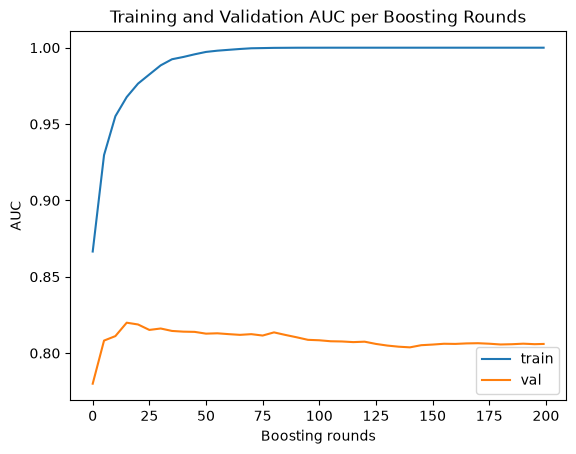

In [91]:
df_score = parse_xgb_output(output)

plt.plot(df_score.num_iter, df_score.train_auc, label='train')
plt.plot(df_score.num_iter, df_score.val_auc, label='val')
plt.xlabel("Boosting rounds")
plt.ylabel("AUC")
plt.title("Training and Validation AUC per Boosting Rounds")
plt.legend();

The train curve goes to one, while the validation curve quickly stops improving.  
This plot is what we will use in the next section for tuning: the number of boosting rounds where the validation AUC peaks tells us how many rounds to use.

## 8. XGBoost Parameter Tuning

In the previous section we trained an XGBoost model with default parameters and learned how to monitor its progress.  
Now **we tune the three most important XGBoost parameters (`eta`, `max_depth` and `min_child_weight`) using the train/validation curves** we learned to parse.

### The parameters to tune

The three parameters we tune are:
1. `eta`: the learning rate. It controls the size of the step each next model takes when correcting the errors of the previous ones.
2. `max_depth`: the maximum depth of each tree.
3. `min_child_weight`: the minimal size of a leaf, the analogue of `min_samples_leaf` in random forest.

<img src="https://github.com/k-candidate/machine-learning-zoomcamp/raw/main/06-trees/images/08-xgb-tuning-01-parameters-imagegen.jpg" alt="XGBoost Parameter Turning" style="max-width: 100%; height: auto; display: block; margin: 0 auto;">

**XGBoost has many more parameters. We tune only these three, in this order: first `eta`, then `max_depth`, then `min_child_weight`**.  
For each parameter we train a model per value, parse the monitoring output with the `parse_xgb_output` function from the previous section, and compare the validation AUC curves.

### Tuning eta

We keep a dictionary `scores` that maps the parameter value to the parsed learning curve. For each value of `eta`, we train a model, capture the output and store the parsed dataframe:

In [92]:
scores = {}

In [93]:
%%capture output

xgb_params = {
    'eta': 0.01,
    'max_depth': 6,
    'min_child_weight': 1,

    'objective': 'binary:logistic',
    'eval_metric': 'auc',

    'nthread': 8,
    'seed': 1,
    'verbosity': 1,
}

model = xgb.train(xgb_params, dtrain, num_boost_round=200,
                  verbose_eval=5,
                  evals=watchlist)

In [94]:
key = 'eta=%s' % (xgb_params['eta'])
scores[key] = parse_xgb_output(output)
key

'eta=0.01'

This gives us `'eta=0.01'`. We repeat this, changing the value of `eta` in the parameters, for 0.3, which is the value we used before, and then 1.0, 0.1 and 0.05. Then we plot the validation AUC of every run on one chart:

In [97]:
# 1. Initialize the storage dictionary
scores = {}

# 2. Define the different learning rates to test
etas = [0.01, 0.05, 0.1, 0.3, 1.0]

# 3. Loop through each eta value
for eta in etas:
    print(f'Training model with eta={eta}...')
    
    # Store evaluation metrics inside this dictionary during training
    evals_result = {}
    
    xgb_params = {
        'eta': eta,
        'max_depth': 6,
        'min_child_weight': 1,
        'objective': 'binary:logistic',
        'eval_metric': 'auc',
        'nthread': 8,
        'seed': 1,
        'verbosity': 1
    }
    
    # Pass evals_result to the train function to capture metrics
    model = xgb.train(
        xgb_params, 
        dtrain, 
        num_boost_round=200, 
        verbose_eval=False,  # Turn off text output since we capture it cleanly
        evals=watchlist,
        evals_result=evals_result
    )
    
    # Extract the AUC lists from the dictionary
    # Note: 'train' and 'val' match the keys used in the `watchlist` tuple
    train_auc = evals_result['train']['auc']
    val_auc = evals_result['val']['auc']
    
    # Create the DataFrame to match the format expected by the plotting step next
    df_score = pd.DataFrame({
        'num_iter': range(1, len(val_auc) + 1),
        'train_auc': train_auc,
        'val_auc': val_auc
    })
    
    # Save to the scores dictionary using the original key format
    key = f'eta={eta}'
    scores[key] = df_score

Training model with eta=0.01...
Training model with eta=0.05...
Training model with eta=0.1...
Training model with eta=0.3...
Training model with eta=1.0...


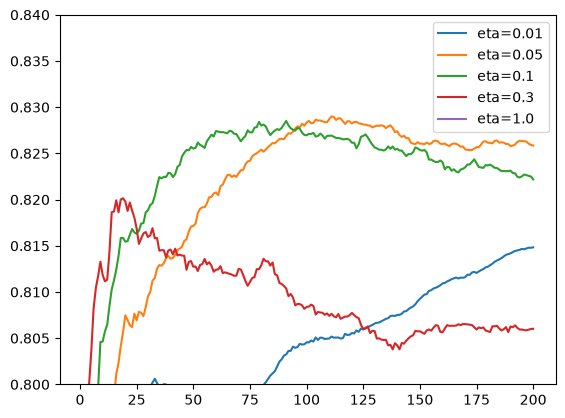

In [98]:
for key, df_score in scores.items():
    plt.plot(df_score.num_iter, df_score.val_auc, label=key)

plt.ylim(0.8, 0.84)
plt.legend()


The learning rate controls how fast the model learns.  
With `eta=1.0` the model takes the full correction from each new tree and quickly saturates: its curve falls below the zoom window.  
With `eta=0.3` the validation AUC rises fast, peaks early and then starts to degrade.  
With `eta=0.01` the curve climbs slowly and would need many more rounds to reach its best.  
The best trade-off is a middle value: `eta=0.1` reaches the top AUC (before `'eta=0.05'`) and stays relatively stable (small vertical change), so we take it.

### Tuning max_depth

Next we fix `eta=0.1` and tune `max_depth` the same way.  
We reset scores to start a fresh comparison, and train with `max_depth` of 6 (the baseline we already have) then 3, 4 and 10:

In [100]:
# 1. Reset scores to start a fresh comparison
scores = {}

# 2. Define the max_depth values to test
max_depths = [3, 4, 6, 10]

# 3. Loop through each max_depth value with eta=0.1 fixed
for depth in max_depths:
    print(f'Training model with max_depth={depth}...')
    
    evals_result = {}
    
    xgb_params = {
        'eta': 0.1,             # Fixed at the optimal value from the previous step
        'max_depth': depth,     # Iterating through depths
        'min_child_weight': 1,
        'objective': 'binary:logistic',
        'eval_metric': 'auc',
        'nthread': 8,
        'seed': 1,
        'verbosity': 1
    }
    
    model = xgb.train(
        xgb_params, 
        dtrain, 
        num_boost_round=200, 
        verbose_eval=False,
        evals=watchlist,
        evals_result=evals_result
    )
    
    train_auc = evals_result['train']['auc']
    val_auc = evals_result['val']['auc']
    
    df_score = pd.DataFrame({
        'num_iter': range(1, len(val_auc) + 1),
        'train_auc': train_auc,
        'val_auc': val_auc
    })
    
    key = f'max_depth={depth}'
    scores[key] = df_score


Training model with max_depth=3...
Training model with max_depth=4...
Training model with max_depth=6...
Training model with max_depth=10...


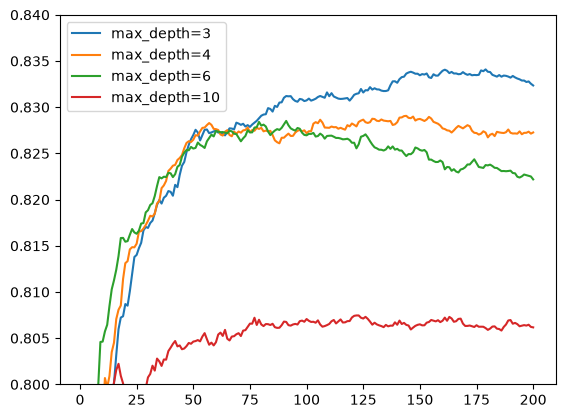

In [102]:
for key, df_score in scores.items():
    plt.plot(df_score.num_iter, df_score.val_auc, label=key)

plt.ylim(0.8, 0.84)
plt.legend();

After plotting all four, the worst is clearly `max_depth=10`, so we remove it from the comparison:

In [106]:
# The try/except is just because I had to re-run the cell. You cannot delete something that has already been deleted.
try:
    del scores['max_depth=10']
except KeyError:
    pass

Then we plot the remaining curves again, zooming in with `plt.ylim(0.8, 0.84)`: `max_depth=6` is the second worst, and the best depth is a small one. `max_depth=3` gives the highest and most stable validation AUC.

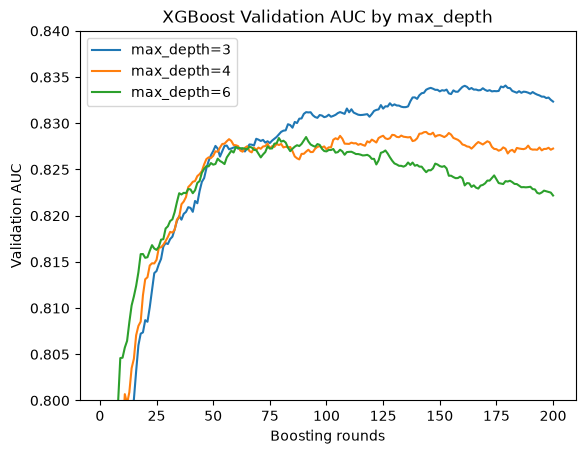

In [108]:

# Plot the remaining depths (3, 4, and 6)
for key, df_score in scores.items():
    plt.plot(df_score.num_iter, df_score.val_auc, label=key)

plt.ylim(0.8, 0.84)

plt.xlabel("Boosting rounds")
plt.ylabel("Validation AUC")
plt.title("XGBoost Validation AUC by max_depth")
plt.legend();

### Tuning min_child_weight

The last parameter is `min_child_weight`.  
We reset scores once more and compare the baseline value of 1 with 10 and 30.

In [109]:
# 1. Reset scores to start a fresh comparison
scores = {}

# 2. Fix eta=0.1, max_depth=3, and define min_child_weight values to test
min_child_weights = [1, 10, 30]

# 3. Loop through each min_child_weight value
for weight in min_child_weights:
    print(f'Training model with min_child_weight={weight}...')
    
    evals_result = {}
    
    xgb_params = {
        'eta': 0.1,                 # Fixed optimal value
        'max_depth': 3,             # Fixed optimal value
        'min_child_weight': weight, # Iterating through weights
        'objective': 'binary:logistic',
        'eval_metric': 'auc',
        'nthread': 8,
        'seed': 1,
        'verbosity': 1
    }
    
    model = xgb.train(
        xgb_params, 
        dtrain, 
        num_boost_round=200, 
        verbose_eval=False,
        evals=watchlist,
        evals_result=evals_result
    )
    
    train_auc = evals_result['train']['auc']
    val_auc = evals_result['val']['auc']
    
    df_score = pd.DataFrame({
        'num_iter': range(1, len(val_auc) + 1),
        'train_auc': train_auc,
        'val_auc': val_auc
    })
    
    key = f'min_child_weight={weight}'
    scores[key] = df_score


Training model with min_child_weight=1...
Training model with min_child_weight=10...
Training model with min_child_weight=30...


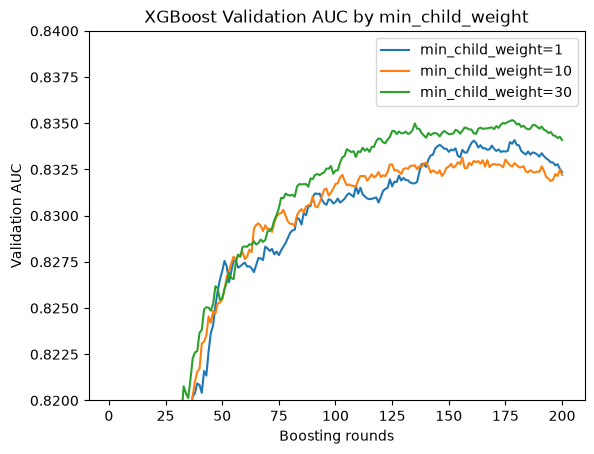

In [111]:
# Plot the results to compare 1, 10, and 30
for key, df_score in scores.items():
    plt.plot(df_score.num_iter, df_score.val_auc, label=key)

plt.ylim(0.82, 0.84)

plt.xlabel("Boosting rounds")
plt.ylabel("Validation AUC")
plt.title("XGBoost Validation AUC by min_child_weight")
plt.legend();

The three curves are close to each other even after zooming in with `plt.ylim(0.82, 0.84)`: for this parameter the differences are small. So we keep the default value, `min_child_weight=1`.

### The final model

Putting it all together: `eta=0.1`, `max_depth=3`, `min_child_weight=1`.  
Looking at the plots, the validation AUC is at its best around 175 boosting rounds, so we train the final model of this section with `num_boost_round=175`:

In [112]:
xgb_params = {
    'eta': 0.1,
    'max_depth': 3,
    'min_child_weight': 1,

    'objective': 'binary:logistic',
    'eval_metric': 'auc',

    'nthread': 8,
    'seed': 1,
    'verbosity': 1,
}

model = xgb.train(xgb_params, dtrain, num_boost_round=175)

Other parameters worth knowing about:
- `subsample`: the fraction of the training data each tree sees.
- `colsample_bytree`: the fraction of features each tree sees, like the random feature subsets of random forest.
- `lambda` and `alpha`: the L2 and L1 regularization terms on the weights.

The full list is in the XGBoost parameter documentation: https://xgboost.readthedocs.io/en/latest/parameter.html.

## 9. Selecting the final model

In this section:
- we compare the three model families we trained in this chapter: decision tree, random forest and XGBoost
- pick the winner
- train the final model on the full training data to check it on the test set.

### Comparing the three models

Each family was tuned to its best parameters in the previous sections, so we train all three on the training data and compare their AUC on the same validation set.

In [ ]:
# The tuned decision tree (max_depth=6 and min_samples_leaf=15) gives:
dt = DecisionTreeClassifier(max_depth=6, min_samples_leaf=15)
dt.fit(X_train, y_train)

y_pred = dt.predict_proba(X_val)[:, 1]
roc_auc_score(y_val, y_pred)

0.7853194400716863

In [114]:
# The tuned random forest (200 trees with max_depth=10 and min_samples_leaf=3) gives:
rf = RandomForestClassifier(n_estimators=200,
                            max_depth=10,
                            min_samples_leaf=3,
                            random_state=1)
rf.fit(X_train, y_train)

y_pred = rf.predict_proba(X_val)[:, 1]
roc_auc_score(y_val, y_pred)

0.8246258264512848

In [115]:
# And the tuned XGBoost model (eta=0.1, max_depth=3, min_child_weight=1, 175 rounds) gives:
xgb_params = {
    'eta': 0.1,
    'max_depth': 3,
    'min_child_weight': 1,

    'objective': 'binary:logistic',
    'eval_metric': 'auc',

    'nthread': 8,
    'seed': 1,
    'verbosity': 1,
}

model = xgb.train(xgb_params, dtrain, num_boost_round=175)

y_pred = model.predict(dval)
roc_auc_score(y_val, y_pred)

0.8334715797631446


| Model | Parameters | Validation AUC |
| :--- | :--- | :--- |
| **Decision tree** | max_depth=6 · min_samples_leaf=15 | 0.7853194400716863 |
| **Random forest** | 200 trees · max_depth=10 · min_samples_leaf=3 | 0.8246258264512848 |
| **XGBoost** | eta=0.1 · max_depth=3 · min_child_weight=1 · 175 rounds | 0.8334715797631446 |

**XGBoost wins** with an AUC of about 0.833, **ahead of random forest** at about 0.825 **and the single decision tree** at about 0.785.  
This is a typical outcome: boosted trees are very strong on tabular data. The price is that XGBoost has many hyperparameters and can overfit quickly, so it needs more attention during tuning than random forest, which works well almost out of the box.

### Training the final model

Now that we have selected the best model and the best parameters, we use the standard final-step recipe: combine the training and validation parts into `df_full_train`, retrain with the same parameters, and evaluate once on the test set (the data we have kept aside until now):

In [116]:
df_full_train = df_full_train.reset_index(drop=True)

y_full_train = (df_full_train.status == 'default').astype(int).values
del df_full_train['status']

We turn both `df_full_train` and the test set into feature matrices with a newly fitted `DictVectorizer`, and wrap them in `DMatrix` objects.  
Note that the test DMatrix needs no labels:

In [117]:
dicts_full_train = df_full_train.to_dict(orient='records')

dv = DictVectorizer(sparse=False)
X_full_train = dv.fit_transform(dicts_full_train)

dicts_test = df_test.to_dict(orient='records')
X_test = dv.transform(dicts_test)

In [119]:
feature_names = dv.get_feature_names_out().tolist()

dfulltrain = xgb.DMatrix(X_full_train, label=y_full_train,
                    feature_names=feature_names)

dtest = xgb.DMatrix(X_test, feature_names=feature_names)

Then we train the final model and look at its AUC on the test data:

In [120]:
xgb_params = {
    'eta': 0.1,
    'max_depth': 3,
    'min_child_weight': 1,

    'objective': 'binary:logistic',
    'eval_metric': 'auc',

    'nthread': 8,
    'seed': 1,
    'verbosity': 1,
}

model = xgb.train(xgb_params, dfulltrain, num_boost_round=175)

In [121]:
y_pred = model.predict(dtest)
roc_auc_score(y_test, y_pred)

0.8299814280826938

The test AUC is about 0.830, close to the 0.833 we saw on validation. There is no big gap between the two, which means the model generalized well: it learned patterns that hold on data it has never seen.

## 10. Summary

- Decision trees learn if-then-else rules from data.
- Finding the best split: select the least impure split. This algorithm can overfit, that's why we control it by limiting the max depth and the size of the group.
- Random forest is a way of combininig multiple decision trees. It should have a diverse set of models to make good predictions.
- Gradient boosting trains model sequentially: each model tries to fix errors of the previous model. XGBoost is an implementation of gradient boosting.